In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.spatial import KDTree
import scipy.signal as signal
%matplotlib inline

In [15]:
# Load data
data = loadmat('sampleEEGdata.mat')
data.keys()

dict_keys(['__header__', '__version__', '__globals__', 'EEG'])

In [16]:
# Initialize Parameters
eeg = data['EEG']
eeg_data = eeg['data'][0, 0]
time_vector = eeg['times'][0, 0][0]
timepoints = len(time_vector)
sampling_rate = eeg['srate'][0, 0][0, 0]
trials = 99
channels = 64
nyquist = int(sampling_rate / 2)

eeg_data.shape, time_vector.shape, sampling_rate

((64, 640, 99), (640,), np.uint16(256))

In [17]:
# Create Signal Vectors From 2 Channels Of Interest
channel_1 = 3
channel_2 = 6

signal_1 = eeg_data[channel_1, :, 0]
signal_2 = eeg_data[channel_2, :, 0]

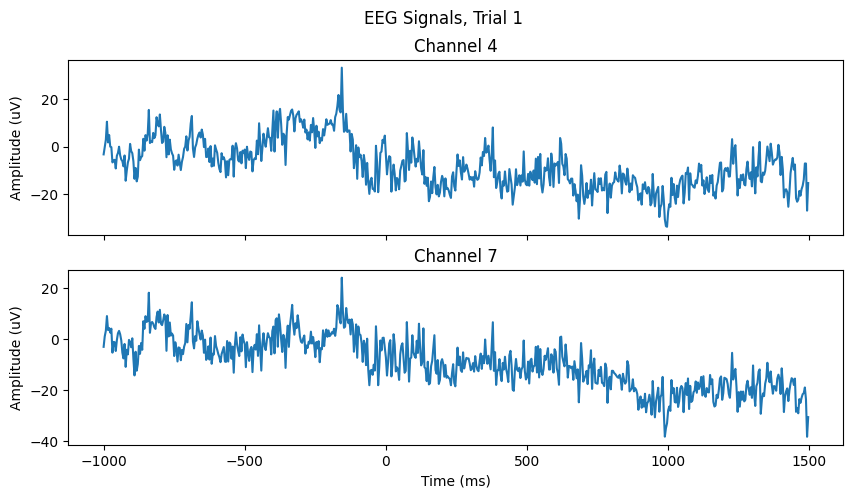

In [18]:
# Visualize Signals
plt.close('all')
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
fig.suptitle('EEG Signals, Trial 1')

ax[0].plot(time_vector, signal_1)
ax[0].set_ylabel('Amplitude (uV)')
ax[0].set_title(f'Channel {channel_1 + 1}')

ax[1].plot(time_vector, signal_2)
ax[1].set_ylabel('Amplitude (uV)')
ax[1].set_xlabel('Time (ms)')
ax[1].set_title(f'Channel {channel_2 + 1}')

plt.show()

In [19]:
# Frequency Multiplication Parameters
frequency = 8
kernel_time = np.arange(-2, 2 - 1/sampling_rate, 1/sampling_rate)

n_conv = timepoints + len(kernel_time) - 1
half_k = int(len(kernel_time) / 2)

fwhm = 0.5

In [20]:
# Create A Complex Morlet Wavelet As Kernel
kern = np.exp(1j * 2 * np.pi * frequency * kernel_time) * np.exp(-4 * np.log(2) * (kernel_time ** 2) / (fwhm ** 2))

kernel_coefs = np.fft.fft(kern, n_conv)
kernel_coefs /= np.max(kernel_coefs)

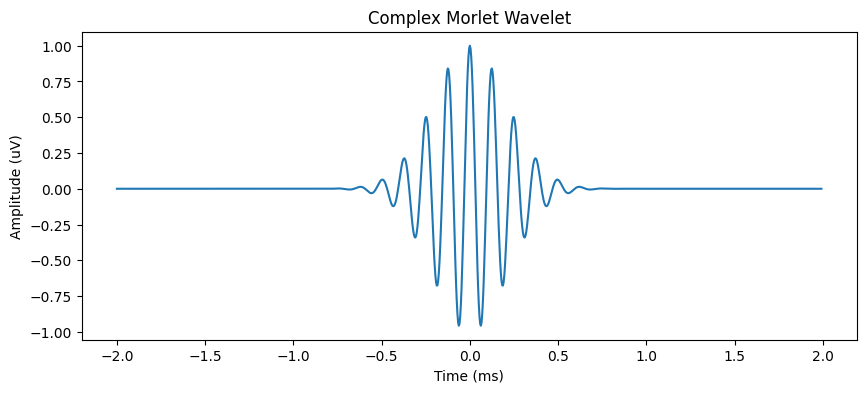

In [21]:
# Visualize Kernel
plt.close('all')
plt.figure(figsize=(10, 4))
plt.plot(kernel_time, kern.real)
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude (uV)')
plt.title('Complex Morlet Wavelet')
plt.show()

In [22]:
# Wavelet Convolution via Frequency Multiplication To Extract Phase From Both Signals
signal_1_coefs = np.fft.fft(signal_1, n_conv)
signal_2_coefs = np.fft.fft(signal_2, n_conv)

result_1 = np.fft.ifft(signal_1_coefs * kernel_coefs)
result_2 = np.fft.ifft(signal_2_coefs * kernel_coefs)

result_1 = result_1[half_k : -half_k]
result_2 = result_2[half_k : -half_k]

phase_1 = np.angle(result_1)
phase_2 = np.angle(result_2)

phase_1.shape, phase_2.shape

((640,), (640,))

In [23]:
# Compute Inter-Site Phase Clustering ( ISPC ) Value To Measure Synchronicity Between The 2 Channels
phase_diff = phase_1 - phase_2

ispc = np.abs(np.mean(np.exp(1j * phase_diff)))
angle = np.angle(np.mean(np.exp(1j * phase_diff)))
ispc

np.float64(0.8623867632015202)

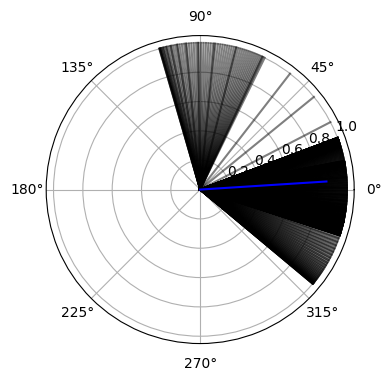

In [24]:
# Plot ISPC On A Polar plot
plt.close('all')
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(10, 4))

ax.plot([np.zeros((timepoints)), phase_diff], [np.zeros((timepoints)), np.ones((timepoints))], 'black', alpha = 0.5)
ax.plot([0, angle], [0, ispc], 'blue', alpha=1)

plt.show()